# Assignment 2: Exercise 2
Try to use your updated multi layer perceptron algorithm to fit and predict the covertype set (on eLearning). To save Don’t forget to preprocess the data accordingly
(Train-test-split, scaling, ...). Play around with the sizes of the model to achieve good results.

## Strategy:
- Overall, this task is pretty simple, as we only have to reuse the implemented functions from the lecture and ex1 on a different exercise
- first I will get all the methods needed
- second, I will prepare and split the data
- At last, I will train it on different model sizes and plot it

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import List, Dict, Optional
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## 1. Setup
- get the methods needed from ex1

### 1.1 Utilities

In [2]:
def one_hot(y: np.ndarray, num_classes: int) -> np.ndarray:
    oh = np.zeros((y.size, num_classes))
    oh[np.arange(y.size), y] = 1.0
    return oh

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def dsigmoid(z):
    s = sigmoid(z)
    return s * (1 - s)

def softmax(logits: np.ndarray) -> np.ndarray:
    z = logits - logits.max(axis=1, keepdims=True)
    expz = np.exp(z)
    return expz / expz.sum(axis=1, keepdims=True)

def cross_entropy(probs: np.ndarray, y_true_oh: np.ndarray, eps: float = 1e-12) -> float:
    p = np.clip(probs, eps, 1.0)
    return -np.mean(np.sum(y_true_oh * np.log(p), axis=1))

def accuracy(y_true, y_pred):
    return (y_true == y_pred).mean()


### 1.2 MLP Class

In [3]:
class MLP:
    def __init__(
        self,
        input_dim: int,
        layer_sizes: List[int],
        num_classes: int,
        seed: Optional[int] = None,
    ):
        self.rng = np.random.default_rng(seed)
        self.shapes = []

        self.act = sigmoid
        self.dact = dsigmoid

        # layer dimensions
        dims = [input_dim] + layer_sizes + [num_classes]
        self.L = len(dims) - 1

        # params init
        self.W = {}
        self.b = {}
        for k in range(1, self.L + 1):
            fan_in, fan_out = dims[k-1], dims[k]
            Wk = np.random.randn(fan_in, fan_out)
            bk = np.zeros((1, fan_out))
            self.W[k] = Wk
            self.b[k] = bk
            self.shapes.append((fan_in, fan_out))

    def forward(self, X: np.ndarray, train: bool = True):
        caches = []
        A = X
        for k in range(1, self.L + 1):
            Z = A @ self.W[k] + self.b[k]
            if k == self.L:
                A_next = softmax(Z)
            else:
                A_next = self.act(Z)
            caches.append((Z, A, self.W[k], self.b[k]))
            A = A_next
        return A, caches

    def backward(self, probs: np.ndarray, y_onehot: np.ndarray, caches: List[tuple]):
        grads_W = {}
        grads_b = {}
        m = y_onehot.shape[0]

        # Initial gradient at output: softmax + cross-entropy
        dA = (probs - y_onehot) / m

        for k in reversed(range(1, self.L + 1)):
            Z, A_prev, Wk, bk = caches[k-1]
            dZ = dA
            if k != self.L:
                dZ = dZ * self.dact(Z)

            dW = A_prev.T @ dZ
            db = np.sum(dZ, axis=0, keepdims=True)
            dA = dZ @ Wk.T

            grads_W[k] = dW
            grads_b[k] = db
        return grads_W, grads_b

    def step(self, grads_W: Dict[int, np.ndarray], grads_b: Dict[int, np.ndarray], lr: float):
        for k in range(1, self.L + 1):
            self.W[k] -= lr * grads_W[k]
            self.b[k] -= lr * grads_b[k]

    def compute_loss(self, probs: np.ndarray, y_onehot: np.ndarray):
        return cross_entropy(probs, y_onehot)

    def predict(self, X: np.ndarray):
        probs, _ = self.forward(X, train=False)
        return np.argmax(probs, axis=1), probs


### 1.3 Training function

In [4]:
def train_batch_learning(
    model: MLP,
    X: np.ndarray,
    y: np.ndarray,
    epochs: int = 100,
    batch_size: int = 64,
    lr: float = 0.5,
    seed: Optional[int] = 123,
    verbose: bool = True
):
    np.random.default_rng(seed)
    num_classes = int(y.max()) + 1
    y_oh = one_hot(y, num_classes)
    history = {"loss": [], "acc": []}

    for epoch in range(1, epochs + 1):
        r = np.arange(X.shape[0])
        np.random.shuffle(r)

        for start_idx in range(0, X.shape[0], batch_size):
            batch_idx = r[start_idx : start_idx + batch_size]
            Xb = X[batch_idx]
            yb_oh = y_oh[batch_idx]

            probs, caches = model.forward(Xb, train=True)
            grads_W, grads_b = model.backward(probs, yb_oh, caches)
            model.step(grads_W, grads_b, lr=lr)

        probs_full, _ = model.forward(X, train=False)
        loss = model.compute_loss(probs_full, y_oh)
        y_pred = np.argmax(probs_full, axis=1)
        acc = accuracy(y, y_pred)
        history["loss"].append(loss)
        history["acc"].append(acc)

        if verbose and (epoch % max(1, epochs // 10) == 0 or epoch <= 5):
            print(f"Epoch {epoch:4d} | loss={loss:.4f} | acc={acc*100:.2f}%")
    return history


## 2. Data preparation
- Load the dataset
- Shift the target column `Cover_Type` from `1..7` to `0..6` so it works with zero-indexed `one_hot` encoding
- Split the data into training (80%) and test (20%) sets
- Scale the features (fitted on the training set only to avoid data leakage)

In [5]:
df = pd.read_csv("../data/CoverTypeSubsampled.csv")

X = df.drop(columns=["Cover_Type"]).to_numpy()
y = df["Cover_Type"].to_numpy() - 1  # shift classes 1-7 to 0-6

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

input_dim = X_train.shape[1]
num_classes = int(y.max()) + 1

## 3. Test the algorithm with different sizes of the model
- I create a list with different hidden layer sizes and test them on the preprocessed dataset.
- Afterwards, I compare their training convergence, test accuracy, and training time.

Small [16]           | train loss=0.5314 | train acc=77.66% | test acc=75.72% | time=4.82s
Medium [32]          | train loss=0.4551 | train acc=80.76% | test acc=79.12% | time=6.10s
Two-Layer [64, 32]   | train loss=0.3019 | train acc=87.64% | test acc=79.83% | time=10.99s
Large [128, 64]      | train loss=0.1607 | train acc=94.06% | test acc=80.67% | time=25.43s


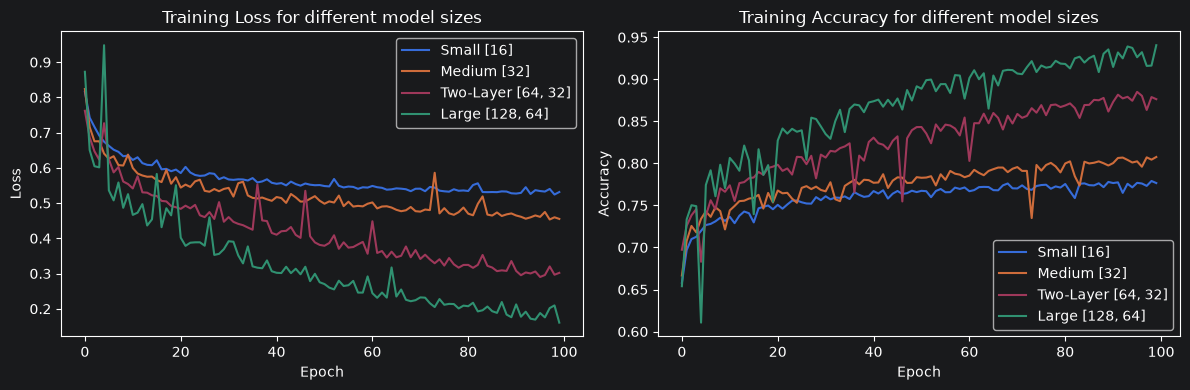

In [6]:
model_configs = [
    ("Small (16)", [16]),
    ("Medium (32)", [32]),
    ("Two-Layer (64, 32)", [64, 32]),
    ("Large (128, 64)", [128, 64]),
]

histories = {}
test_accuracies = {}

for label, layer_sizes in model_configs:
    np.random.seed(42)
    model = MLP(input_dim=input_dim, layer_sizes=layer_sizes, num_classes=num_classes, seed=42)

    start_time = time.time()
    hist = train_batch_learning(
        model, X_train, y_train,
        epochs=100, batch_size=64, lr=0.5, seed=123, verbose=False
    )
    elapsed = time.time() - start_time

    y_test_pred, _ = model.predict(X_test)
    test_acc = accuracy(y_test, y_test_pred)

    histories[label] = hist
    test_accuracies[label] = test_acc

    print(
        f"{label:20s} | train loss={hist['loss'][-1]:.4f} | "
        f"train acc={hist['acc'][-1]*100:.2f}% | test acc={test_acc*100:.2f}% | time={elapsed:.2f}s"
    )

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
for label, hist in histories.items():
    plt.plot(hist["loss"], label=label)
plt.title("Training Loss for different model sizes")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
for label, hist in histories.items():
    plt.plot(hist["acc"], label=label)
plt.title("Training Accuracy for different model sizes")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


### 3.1 Discussion

- **Preprocessing:**
    - Feature scaling is essential here because features like Elevation or Horizontal_Distance_To_Roadways have much larger values than the binary soil/wilderness columns. Without scaling, the sigmoid activations saturate immediately and the model barely learns.
- **Effect of model size:**
    - **Small:** Has limited capacity, resulting in the slowest convergence and lowest accuracy (~75% test accuracy).
    - **Medium and Two-Layer:** Adding more neurons and a second hidden layer noticeably improves both training and test accuracy (~79% test accuracy) with only a small increase in training time.
    - **Large (128, 64):** Reaches the highest training accuracy, but the test accuracy (~80%) barely improves over (64, 32). This growing gap between test and training accuracy may be linked to overfitting. Additionally, the large network takes a lot more computing time than the rest.
- **Conclusion:**
    - A medium two-layer architecture like (64, 32) offers the best trade-off between generalization on unseen test data and computational cost.

# AI Usage / Prompts:
- what do I have to be careful about preprocessing this dataset, before using it for my mlp